# CIFAR-100 exploratory data analysis

This notebook looks at the **original CIFAR-100** release before any training augmentation.

Nothing is dropped. There is no subset, no class removed, and no image resized away from 32×32. Train has 50,000 images. Test has 10,000 images.

## Why you do not see a folder of pictures

The download is `data/cifar-100-python.tar.gz`. That archive is already extracted to `data/cifar-100-python/`. Inside it you will find three files, not thousands of `.jpg` files:

- `train` — all 50,000 training images packed into one file
- `test` — all 10,000 test images packed into one file
- `meta` — the 100 class names and the 20 superclass names

CIFAR-100 was released this way in 2009. Each image is 32×32×3, so the authors stored the pixels in a Python pickle instead of one file per photo. This notebook unpacks those pixels and displays them.

Preprocessing (crop, flip, normalize) is a different notebook: `01_cifar100_pipeline.ipynb`. This one stops at "what is the data?"


Steps 1–10 answer "what is in the files?". Steps 11–19 go through the rest of a standard image-dataset checklist: the train/test split, the class hierarchy, random and same-class photos, broken images, per-channel pixel statistics, whether classes separate in pixel space, duplicate and extreme images, and the augmentations the training recipe will use.

## Step 1. Point at the extracted files

`Path` is just a safer way to write a folder path. `REPO_ROOT` is the project folder. If the notebook kernel was started inside `notebooks/`, the `src` folder is not in the current directory, so we step up one level.


In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np

# Folder that contains data/ and notebooks/.
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data" / "cifar-100-python"
print("data folder:", DATA_DIR)
print("files:", sorted(p.name for p in DATA_DIR.iterdir()))


data folder: /Users/sufyan.siddiqui/ML-Project/data/cifar-100-python
files: ['file.txt~', 'meta', 'test', 'train']


## Step 2. Open the packed files

`pickle` is Python's format for saving a dictionary to disk. `encoding="bytes"` matters because this file was written by Python 2. The dictionary keys are byte strings such as `b"data"`, not normal `"data"`.

After this cell, `train_blob` is one dictionary holding every training image. We have not dropped any rows.


In [2]:
def unpickle(path):
    # "rb" means read the file as bytes, not as text.
    with path.open("rb") as handle:
        return pickle.load(handle, encoding="bytes")

train_blob = unpickle(DATA_DIR / "train")
test_blob = unpickle(DATA_DIR / "test")
meta = unpickle(DATA_DIR / "meta")

print("train keys:", sorted(train_blob.keys()))
print("test keys:", sorted(test_blob.keys()))
print("meta keys:", sorted(meta.keys()))


train keys: [b'batch_label', b'coarse_labels', b'data', b'filenames', b'fine_labels']
test keys: [b'batch_label', b'coarse_labels', b'data', b'filenames', b'fine_labels']
meta keys: [b'coarse_label_names', b'fine_label_names']


## Step 3. What one image looks like before we reshape it

`train_blob[b"data"]` is a table of numbers. One row is one image. Each row has 3,072 numbers because 32 × 32 × 3 = 3,072. The order inside a row is not "pixel, pixel, pixel". It is the full red plane, then the full green plane, then the full blue plane.

`b"fine_labels"` is the class id from 0 to 99. `b"coarse_labels"` is the superclass id from 0 to 19. CIFAR-100 gives every image both. The DKD paper classifies the 100 fine classes. The superclass is only there so we can see which fine classes are related.


In [3]:
raw_row = train_blob[b"data"][0]
print("one image as stored, shape:", raw_row.shape, "dtype:", raw_row.dtype)
print("first 5 numbers:", raw_row[:5])
print("fine label id:", train_blob[b"fine_labels"][0])
print("coarse label id:", train_blob[b"coarse_labels"][0])
print("filename:", train_blob[b"filenames"][0])


one image as stored, shape: (3072,) dtype: uint8
first 5 numbers: [255 255 255 255 255]
fine label id: 19
coarse label id: 11
filename: b'bos_taurus_s_000507.png'


## Step 4. Turn that row into a picture

`reshape(3, 32, 32)` groups the 3,072 numbers into red, green, and blue planes of 32×32.

`transpose(1, 2, 0)` swaps the axes from "channel, height, width" to "height, width, channel". `imshow` expects the second layout. After this, the array is a normal tiny RGB image and we can plot it.

This is image 0 only. The next cell does the same reshape for every image.


picture shape: (32, 32, 3) dtype: uint8


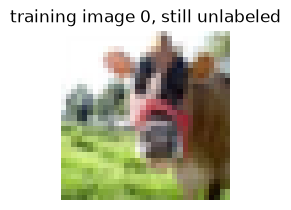

In [4]:
one_image = raw_row.reshape(3, 32, 32).transpose(1, 2, 0)
print("picture shape:", one_image.shape, "dtype:", one_image.dtype)

plt.figure(figsize=(2.2, 2.2))
plt.imshow(one_image)
plt.title("training image 0, still unlabeled")
plt.axis("off")
plt.show()


## Step 5. Load every image

Same reshape as above, applied to the whole table. `-1` means "however many rows there are". We do not slice the table, so this is the full split.

Class names live in `meta`. They are byte strings (`b"apple"`), so `decode` turns them into normal text.


In [5]:
def images_from_blob(blob):
    flat = np.asarray(blob[b"data"], dtype=np.uint8)
    # (N, 3072) -> (N, 3, 32, 32) -> (N, 32, 32, 3)
    return flat.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

def decode_names(raw_names):
    return [name.decode("utf-8") if isinstance(name, bytes) else str(name) for name in raw_names]

train_images = images_from_blob(train_blob)
test_images = images_from_blob(test_blob)
train_fine = np.asarray(train_blob[b"fine_labels"], dtype=np.int64)
test_fine = np.asarray(test_blob[b"fine_labels"], dtype=np.int64)
train_coarse = np.asarray(train_blob[b"coarse_labels"], dtype=np.int64)
test_coarse = np.asarray(test_blob[b"coarse_labels"], dtype=np.int64)
fine_names = decode_names(meta[b"fine_label_names"])
coarse_names = decode_names(meta[b"coarse_label_names"])

print("train images:", train_images.shape)
print("test images:", test_images.shape)
print("number of fine class names:", len(fine_names))
print("number of superclass names:", len(coarse_names))
print("image 0 is a:", fine_names[int(train_fine[0])], "/", coarse_names[int(train_coarse[0])])


train images: (50000, 32, 32, 3)
test images: (10000, 32, 32, 3)
number of fine class names: 100
number of superclass names: 20
image 0 is a: cattle / large_omnivores_and_herbivores


## Step 6. Counts, and the check that we did not shrink the dataset

`bincount` counts how many times each class id appears. `minlength=100` forces a slot for every class, including a class that might have been missing. If a class had zero images, the minimum would be 0. It is not.

The original CIFAR-100 release is exactly these two numbers: 50,000 train and 10,000 test. If either number were smaller, we would be looking at a subset. They are not.


In [6]:
train_per_class = np.bincount(train_fine, minlength=100)
test_per_class = np.bincount(test_fine, minlength=100)
train_per_superclass = np.bincount(train_coarse, minlength=20)

print("train images:", len(train_images))
print("test images:", len(test_images))
print("fine classes:", len(fine_names))
print("superclasses:", len(coarse_names))
print("train images per class, min/max:", int(train_per_class.min()), int(train_per_class.max()))
print("test images per class, min/max:", int(test_per_class.min()), int(test_per_class.max()))
print("train images per superclass, min/max:", int(train_per_superclass.min()), int(train_per_superclass.max()))


train images: 50000
test images: 10000
fine classes: 100
superclasses: 20
train images per class, min/max: 500 500
test images per class, min/max: 100 100
train images per superclass, min/max: 2500 2500


## Step 7. Class balance

Each bar is one of the 100 fine classes. The height is the number of training images. A balanced dataset is a flat line. CIFAR-100 is flat: 500 training images in every class, and 100 test images in every class.

That is why the later metric can be plain top-1 accuracy. No class is large enough to dominate the score.


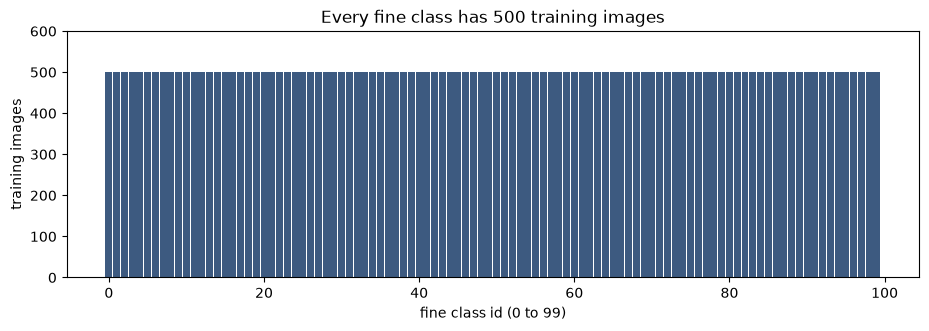

In [7]:
plt.figure(figsize=(11, 3.2))
plt.bar(np.arange(100), train_per_class, color="#3d5a80", width=0.9)
plt.xlabel("fine class id (0 to 99)")
plt.ylabel("training images")
plt.title("Every fine class has 500 training images")
plt.ylim(0, 600)
plt.show()


## Step 8. Look at actual images

The first row is five classes from different superclasses, so you can see how small 32×32 is. The second row is the five fine classes inside `vehicles_1`. They share a superclass and they are still different labels: bicycle, bus, motorcycle, pickup truck, train. At this resolution those are easy to confuse. That is a property of the dataset, not something we filter out.


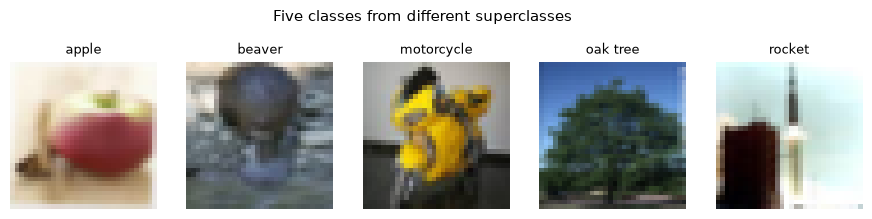

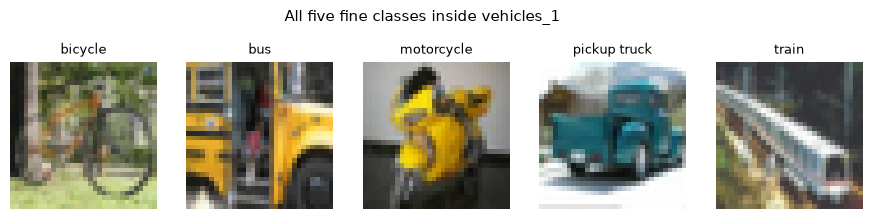

In [8]:
def show_classes(class_names, title):
    name_to_id = {name: i for i, name in enumerate(fine_names)}
    ids = [name_to_id[name] for name in class_names]
    fig, axes = plt.subplots(1, len(ids), figsize=(2.2 * len(ids), 2.6))
    for ax, class_id in zip(axes, ids):
        # First training image whose fine label equals this class.
        index = int(np.flatnonzero(train_fine == class_id)[0])
        ax.imshow(train_images[index])
        ax.set_title(fine_names[class_id].replace("_", " "), fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.show()

show_classes(
    ["apple", "beaver", "motorcycle", "oak_tree", "rocket"],
    "Five classes from different superclasses",
)
show_classes(
    ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],
    "All five fine classes inside vehicles_1",
)


## Step 9. Missing values and broken images

There is no separate "missing" column. An image is missing data only if a pixel is absent or is not a normal color value. These arrays are `uint8`, so every pixel is an integer from 0 to 255. `NaN` cannot occur in that dtype. We still print the min and max so the check is visible.

We do not delete the very dark or very bright images. They are part of the original set.


In [9]:
print("dtype:", train_images.dtype)
print("pixel min / max, train:", int(train_images.min()), int(train_images.max()))
print("pixel min / max, test:", int(test_images.min()), int(test_images.max()))
print("any non-finite train pixel?", not np.isfinite(train_images).all())
print("label ids outside 0..99?", int(train_fine.min()), int(train_fine.max()))


dtype: uint8
pixel min / max, train: 0 255
pixel min / max, test: 0 255
any non-finite train pixel? False
label ids outside 0..99? 0 99


## Step 10. How bright the images are

For each training image, take the mean of all of its pixels and divide by 255 so the result is between 0 and 1. Then plot that list. This is one summary number per image, not a filter.

The 1st percentile, the median, and the 99th percentile say how dark the dark tail is and how bright the bright tail is. We record them. We do not remove those images.


brightness 1st percentile: 0.168
brightness median:         0.464
brightness 99th percentile: 0.872


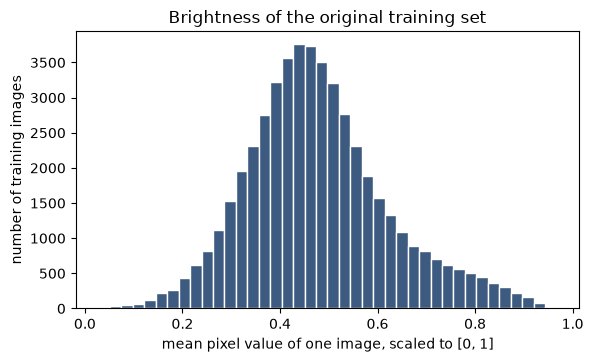

In [10]:
brightness = train_images.astype(np.float64).mean(axis=(1, 2, 3)) / 255.0
p01, p50, p99 = np.quantile(brightness, [0.01, 0.50, 0.99])
print("brightness 1st percentile: %.3f" % p01)
print("brightness median:         %.3f" % p50)
print("brightness 99th percentile: %.3f" % p99)

plt.figure(figsize=(6.5, 3.6))
plt.hist(brightness, bins=40, color="#3d5a80", edgecolor="white")
plt.xlabel("mean pixel value of one image, scaled to [0, 1]")
plt.ylabel("number of training images")
plt.title("Brightness of the original training set")
plt.show()


## Where the remaining checklist items are

Steps 1–10 already checked the packed files, the 32×32×3 shape, the 100 names, the flat class counts, a handful of photos, and brightness. The table maps the rest of a standard image EDA list onto the cells below.

| Checklist item | What this notebook does |
|---|---|
| Image size and pixel type | Steps 5 and 9. Step 11 prints the split counts in one place. |
| Train, validation, and test counts | Step 11. CIFAR-100 ships train and test only. |
| Fine classes, superclasses, imbalance | Steps 6–7 and Step 12. |
| Random images, and several images of one class | Step 13. Step 8 showed a single photo per class. |
| Broken or empty images | Step 9 checked the 0–255 range. Step 14 counts black, white, flat, and one-channel images. |
| Mean, standard deviation, pixel histograms | Step 15. Step 10 was brightness of each image, which is a different number. |
| Do the classes form groups? | Step 16, using the raw pixels and PCA. |
| Duplicates and train/test leakage | Step 17. |
| Extremely dark or bright images | Step 18. |
| Augmentations, and whether they keep the label | Step 19. |


## Step 11. Train, validation, and test

The checklist asks for three counts. CIFAR-100's official release has two files: `train` and `test`. There is no validation file and no validation column.

The DKD paper's CIFAR-100 tables score the official test set. This notebook leaves both files whole. It does not hold out a slice of the 50,000 and call it validation.

Every row in those files is the same length, 3,072 numbers, so every image is 32×32×3. A ragged dataset would have shown up as rows of different lengths. These rows do not.


In [11]:
print("training images:   ", train_images.shape[0])
print("validation images:  0  (no validation file in the CIFAR-100 release)")
print("test images:        ", test_images.shape[0])
print("each image shape:   ", train_images.shape[1:])
print("stored dtype:       ", train_images.dtype, "(integers 0 to 255)")
print("values the model will see later: float32 scaled to [0, 1], then normalized")


training images:    50000
validation images:  0  (no validation file in the CIFAR-100 release)
test images:         10000
each image shape:    (32, 32, 3)
stored dtype:        uint8 (integers 0 to 255)
values the model will see later: float32 scaled to [0, 1], then normalized


## Step 12. The 20 superclasses, and the 5 fine classes inside each one

Every training image has two labels. The fine label is the thing in the photo (`apple`, `bus`). The coarse label is the group that thing belongs to (`fruit_and_vegetables`, `vehicles_1`). The DKD experiment classifies the 100 fine labels. The superclass is how we talk about which fine labels are related.

CIFAR-100 puts exactly five fine classes in each superclass. The cell checks that a fine class never appears under two superclasses, then lists the groups. The bar chart is the superclass version of Step 7. Each bar should be 2,500 training images, because 5 classes × 500 images.


superclasses per fine class, min/max: 1 1

 0  aquatic mammals: beaver, dolphin, otter, seal, whale
 1  fish: aquarium fish, flatfish, ray, shark, trout
 2  flowers: orchid, poppy, rose, sunflower, tulip
 3  food containers: bottle, bowl, can, cup, plate
 4  fruit and vegetables: apple, mushroom, orange, pear, sweet pepper
 5  household electrical devices: clock, keyboard, lamp, telephone, television
 6  household furniture: bed, chair, couch, table, wardrobe
 7  insects: bee, beetle, butterfly, caterpillar, cockroach
 8  large carnivores: bear, leopard, lion, tiger, wolf
 9  large man-made outdoor things: bridge, castle, house, road, skyscraper
10  large natural outdoor scenes: cloud, forest, mountain, plain, sea
11  large omnivores and herbivores: camel, cattle, chimpanzee, elephant, kangaroo
12  medium mammals: fox, porcupine, possum, raccoon, skunk
13  non-insect invertebrates: crab, lobster, snail, spider, worm
14  people: baby, boy, girl, man, woman
15  reptiles: crocodile, dinos

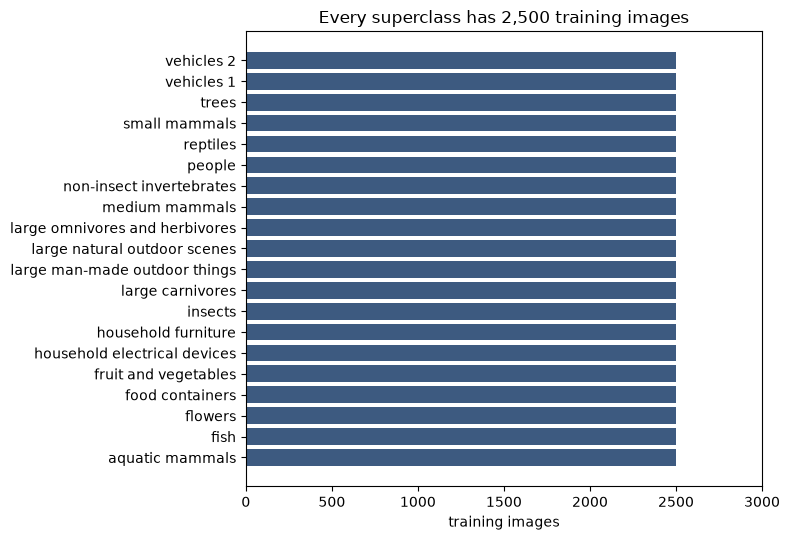

In [12]:
# A fine class should sit under one superclass only.
superclasses_per_fine = [
    len(np.unique(train_coarse[train_fine == fine_id])) for fine_id in range(100)
]
print("superclasses per fine class, min/max:", min(superclasses_per_fine), max(superclasses_per_fine))

print()
for coarse_id, coarse_name in enumerate(coarse_names):
    member_ids = np.unique(train_fine[train_coarse == coarse_id])
    members = ", ".join(fine_names[int(i)].replace("_", " ") for i in member_ids)
    print(f"{coarse_id:2d}  {coarse_name.replace('_', ' ')}: {members}")

plt.figure(figsize=(8, 5.5))
plt.barh(
    [name.replace("_", " ") for name in coarse_names],
    train_per_superclass,
    color="#3d5a80",
)
plt.xlabel("training images")
plt.title("Every superclass has 2,500 training images")
plt.xlim(0, 3000)
plt.tight_layout()
plt.show()


## Step 13. Random photos, then several photos of the same class

Step 8 showed the first training photo of a few classes. That is one example, so it hides how much a class varies.

The first grid is a random draw from the whole training set. Seed 0 keeps the draw the same if you run the cell again. The labels on the tiles are the fine names. This is the place to notice three dataset facts: the photos are tiny, the object usually fills the frame, and the background is still cluttered.

The next two grids are eight random training photos of `apple`, then eight of `chair`. Same label, different colors, angles, and backgrounds. That spread is intra-class variance. A model has to treat all eight apples as one class.


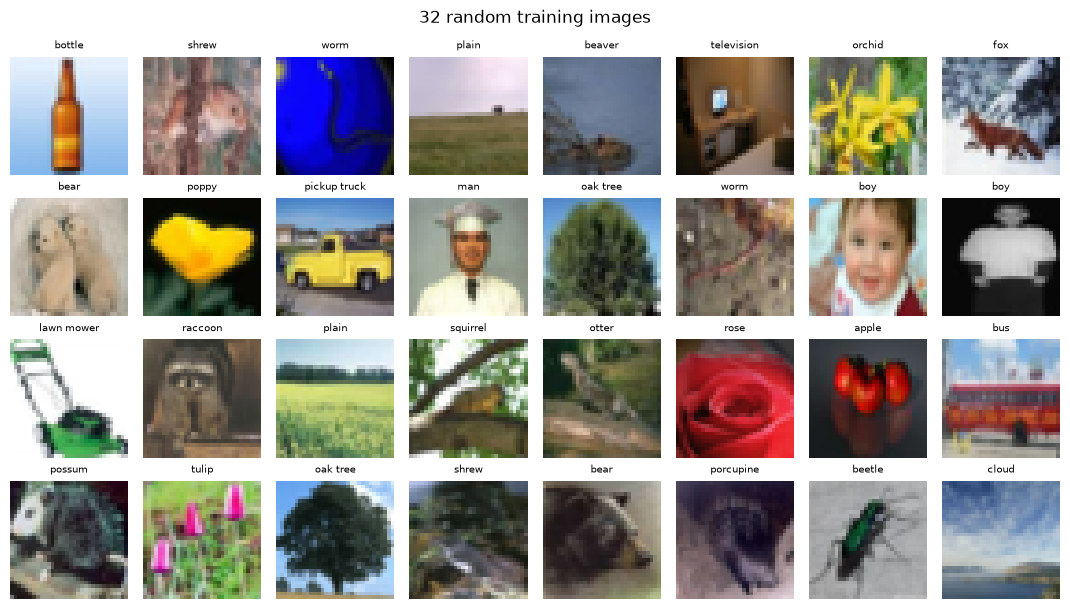

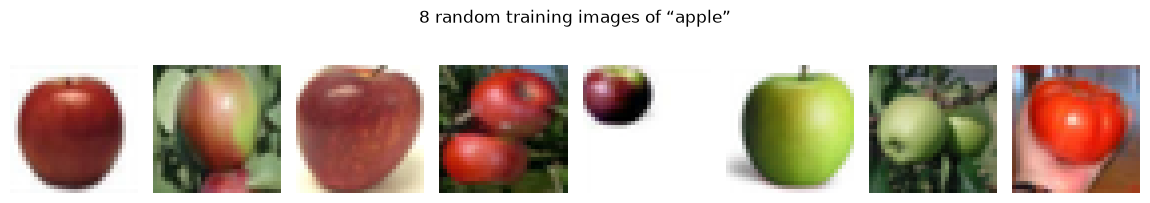

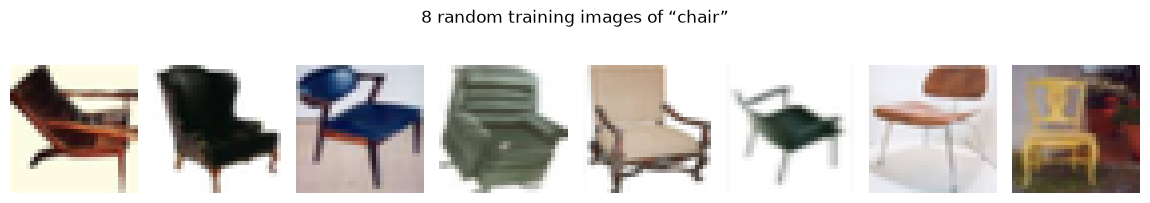

In [13]:
def show_random_images(images, labels, names, rows, cols, seed, title):
    rng = np.random.default_rng(seed)
    picked = rng.choice(len(images), size=rows * cols, replace=False)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.35, rows * 1.55))
    for ax, index in zip(axes.ravel(), picked):
        ax.imshow(images[index])
        ax.set_title(names[int(labels[index])].replace("_", " "), fontsize=7)
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


def show_one_class(class_name, n, seed):
    class_id = fine_names.index(class_name)
    pool = np.flatnonzero(train_fine == class_id)
    rng = np.random.default_rng(seed)
    picked = rng.choice(pool, size=n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(1.45 * n, 2.15))
    for ax, index in zip(axes, picked):
        ax.imshow(train_images[index])
        ax.axis("off")
    fig.suptitle(f"{n} random training images of “{class_name}”", fontsize=12)
    plt.tight_layout()
    plt.show()


show_random_images(
    train_images,
    train_fine,
    fine_names,
    rows=4,
    cols=8,
    seed=0,
    title="32 random training images",
)
show_one_class("apple", n=8, seed=0)
show_one_class("chair", n=8, seed=0)


## Step 14. Black, white, flat, and one-channel images

Step 9 showed that every pixel is a normal integer from 0 to 255. This cell asks a narrower question: is the whole image useless?

- **All black:** every pixel is 0.
- **All white:** every pixel is 255.
- **Flat:** every pixel in the image is the same value, so there is no object to see.
- **Missing channel:** one of red, green, or blue is entirely 0.

The counts cover the training set and the test set. A count of zero means that kind of image is not in the file. These images would stay in the set if any were found. The check is a measurement, not a filter.


In [14]:
def image_faults(images):
    all_black = np.all(images == 0, axis=(1, 2, 3))
    all_white = np.all(images == 255, axis=(1, 2, 3))
    flat = images.max(axis=(1, 2, 3)) == images.min(axis=(1, 2, 3))
    # max over height and width: a channel is "missing" when it is all zeros.
    channel_is_zero = images.max(axis=(1, 2)) == 0
    missing_channel = channel_is_zero.any(axis=1)
    return {
        "all black": int(all_black.sum()),
        "all white": int(all_white.sum()),
        "flat color": int(flat.sum()),
        "a channel is all zeros": int(missing_channel.sum()),
    }


for split_name, split_images in (("train", train_images), ("test", test_images)):
    print(split_name)
    for fault_name, count in image_faults(split_images).items():
        print(f"  {fault_name}: {count}")


train
  all black: 0
  all white: 0
  flat color: 0
  a channel is all zeros: 0
test
  all black: 0
  all white: 0
  flat color: 0
  a channel is all zeros: 0


## Step 15. Mean, standard deviation, and pixel histograms

Step 10 averaged each image down to one brightness number, then plotted those 50,000 numbers. This step keeps every pixel.

**Channel mean.** Average of the red values across every training pixel, then the same for green and blue, after dividing by 255. These three numbers are what training subtracts.

**Channel standard deviation.** How far those same pixels spread around the mean. Training divides by these three numbers after the subtraction. The division uses the population standard deviation (divide by the number of pixels).

**Global mean.** The average of every pixel in every channel. It is the ordinary average of the three channel means, because each channel has the same number of pixels.

The printed "recipe" row is the constant triple stored for the DKD CIFAR-100 run (`0.5071, 0.4867, 0.4408` and `0.2675, 0.2565, 0.2761`). The cell recomputes the statistics from this file so we can see that the constants match the data. Training will keep the recipe constants.

The histograms count pixel values from 0 to 255 in each channel. A pile-up at 0 or at 255 would mean a lot of clipped black or white. Brightness in Step 10 cannot show that, because averaging an image hides a clipped channel.


training-set channel mean (R, G, B): [0.5071 0.4865 0.4409]
training-set channel std  (R, G, B): [0.2673 0.2564 0.2762]
recipe mean:                          [0.5071 0.4867 0.4408]
recipe std:                           [0.2675 0.2565 0.2761]
global mean, all channels:            0.4782


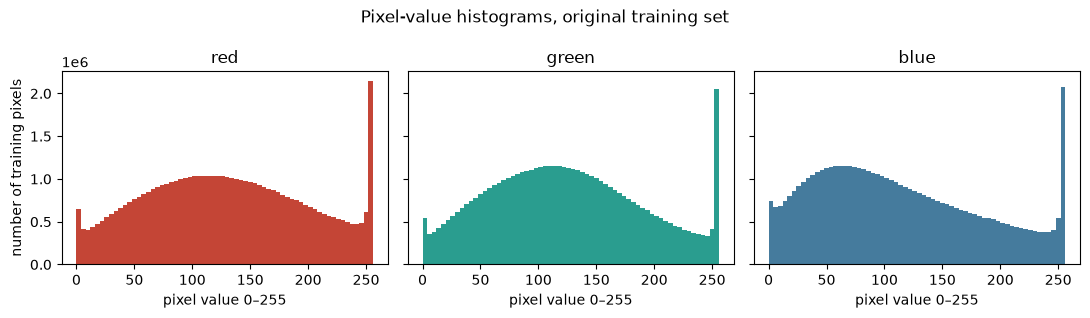

In [15]:
RECIPE_MEAN = np.array([0.5071, 0.4867, 0.4408], dtype=np.float64)
RECIPE_STD = np.array([0.2675, 0.2565, 0.2761], dtype=np.float64)

channel_mean = np.zeros(3, dtype=np.float64)
channel_std = np.zeros(3, dtype=np.float64)
for channel in range(3):
    values = train_images[..., channel].astype(np.float32)
    channel_mean[channel] = values.mean() / 255.0
    channel_std[channel] = values.std() / 255.0

global_mean = float(channel_mean.mean())
print("training-set channel mean (R, G, B):", np.round(channel_mean, 4))
print("training-set channel std  (R, G, B):", np.round(channel_std, 4))
print("recipe mean:                         ", RECIPE_MEAN)
print("recipe std:                          ", RECIPE_STD)
print("global mean, all channels:           ", round(global_mean, 4))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
channel_titles = ["red", "green", "blue"]
channel_colors = ["#c44536", "#2a9d8f", "#457b9d"]
for channel in range(3):
    counts, edges = np.histogram(train_images[..., channel], bins=64, range=(0, 256))
    centers = (edges[:-1] + edges[1:]) / 2.0
    axes[channel].bar(centers, counts, width=4.0, color=channel_colors[channel])
    axes[channel].set_title(channel_titles[channel])
    axes[channel].set_xlabel("pixel value 0–255")
axes[0].set_ylabel("number of training pixels")
fig.suptitle("Pixel-value histograms, original training set", fontsize=12)
plt.tight_layout()
plt.show()


## Step 16. Do the classes separate if we only look at pixels?

A later model will be a convolutional network. This cell does not train one. It asks a prior question: if each photo is just its 3,072 pixel numbers, do the classes already sit in separate groups?

**Flatten.** One 32×32×3 image becomes a vector of length 3,072. Red pixels, then the layout is just a long list of the values already in the array.

**Why these vectors, and not a pretrained ResNet.** A ResNet trained on some other dataset would describe the photo in that network's features. That is a different question, and this project has not trained a model. The vectors here are the CIFAR-100 pixels.

**PCA.** Principal component analysis finds new axes that keep as much of the pixel variation as possible. The plot uses the first two axes. Each column (one pixel position and one color) is centered first: we subtract the average value at that position, computed on the sample. We do not divide by each position's standard deviation.

The scatter plot is 4,000 training images, drawn with seed 0. The full 50,000 stay in the dataset. Two thousand would be enough to see the shape; 4,000 keeps the cloud readable. Color is the superclass, because 100 colors cannot be read.

The second plot uses the same two axes and only the five fine classes inside `vehicles_1`. Separate blobs would mean those five vehicles are easy to tell apart from pixels alone. Overlap means they are not.

**t-SNE and UMAP** are other ways to draw a 2D map. PCA is the one drawn here because it is linear, it reports how much variation the axes keep, and it runs from NumPy. The spoken result is the overlap and the variance numbers, not the name of the algorithm.

Two axes will keep only a small share of the variation. The printed "components to reach 90%" line says how many axes you would need to keep most of the pixel variation. A large number means the photos do not lie on a small flat sheet.


images in the PCA sample: 4000   vector length: 3072
share of variance on axis 1:        32.5%
share of variance on axis 2:        9.4%
share kept by the first 10 axes:    68.4%
share kept by the first 50 axes:    85.8%
axes needed to keep 90% of variance: 85


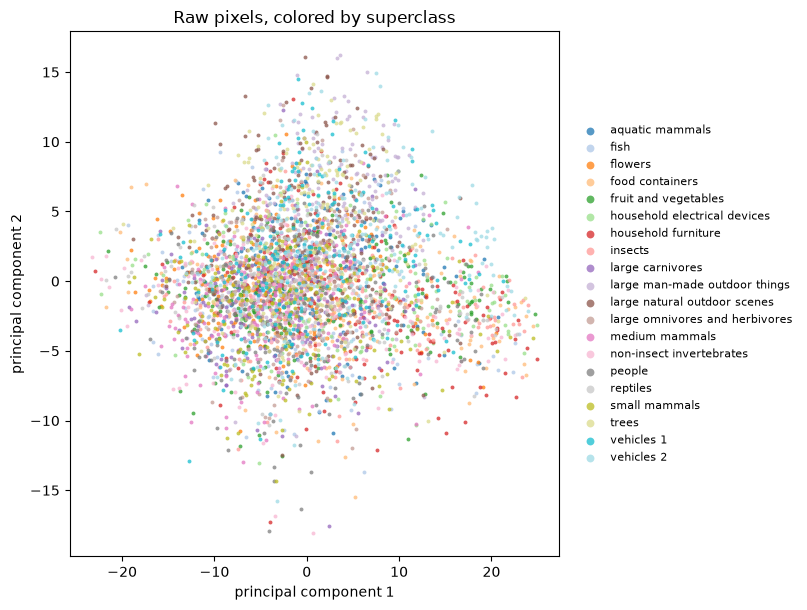

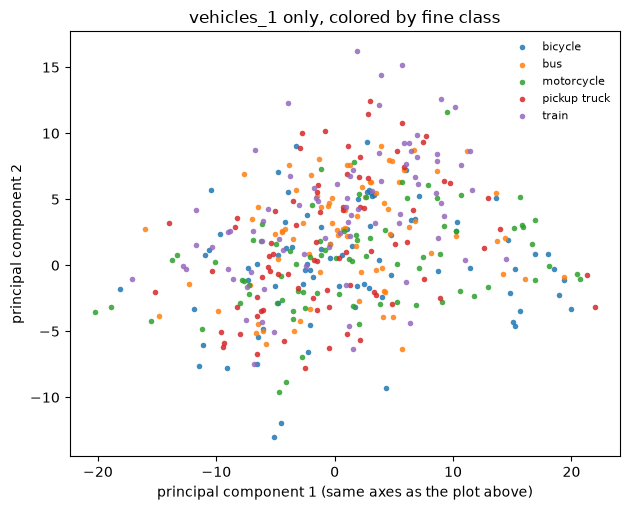

In [16]:
rng = np.random.default_rng(0)
sample_size = 4000
sample_index = rng.choice(len(train_images), size=sample_size, replace=False)

sample = train_images[sample_index].astype(np.float32).reshape(sample_size, -1) / 255.0
feature_mean = sample.mean(axis=0)
centered = sample - feature_mean
# Economy SVD. Rows are images, columns are the 3,072 pixel positions.
_u, singular_values, components = np.linalg.svd(centered, full_matrices=False)
coords = centered @ components[:2].T

variance_share = (singular_values ** 2) / np.sum(singular_values ** 2)
cumulative = np.cumsum(variance_share)
components_for_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print("images in the PCA sample:", sample_size, "  vector length:", centered.shape[1])
print("share of variance on axis 1:        %.1f%%" % (100 * variance_share[0]))
print("share of variance on axis 2:        %.1f%%" % (100 * variance_share[1]))
print("share kept by the first 10 axes:    %.1f%%" % (100 * variance_share[:10].sum()))
print("share kept by the first 50 axes:    %.1f%%" % (100 * variance_share[:50].sum()))
print("axes needed to keep 90% of variance:", components_for_90)

fig, ax = plt.subplots(figsize=(8.2, 6.2))
cmap = plt.colormaps["tab20"]
sample_coarse = train_coarse[sample_index]
for coarse_id, coarse_name in enumerate(coarse_names):
    mask = sample_coarse == coarse_id
    ax.scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=8,
        alpha=0.75,
        color=cmap(coarse_id),
        linewidths=0,
        label=coarse_name.replace("_", " "),
    )
ax.set_xlabel("principal component 1")
ax.set_ylabel("principal component 2")
ax.set_title("Raw pixels, colored by superclass")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8, frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

vehicle_id = coarse_names.index("vehicles_1")
vehicle_fine_ids = np.unique(train_fine[train_coarse == vehicle_id])
zoom_index = np.concatenate(
    [
        rng.choice(np.flatnonzero(train_fine == int(fine_id)), size=80, replace=False)
        for fine_id in vehicle_fine_ids
    ]
)
zoom = train_images[zoom_index].astype(np.float32).reshape(len(zoom_index), -1) / 255.0
zoom_coords = (zoom - feature_mean) @ components[:2].T

fig, ax = plt.subplots(figsize=(6.4, 5.2))
for color_index, fine_id in enumerate(vehicle_fine_ids):
    mask = train_fine[zoom_index] == int(fine_id)
    ax.scatter(
        zoom_coords[mask, 0],
        zoom_coords[mask, 1],
        s=16,
        alpha=0.85,
        linewidths=0,
        label=fine_names[int(fine_id)].replace("_", " "),
    )
ax.set_xlabel("principal component 1 (same axes as the plot above)")
ax.set_ylabel("principal component 2")
ax.set_title("vehicles_1 only, colored by fine class")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## Step 17. Copies, and copies that leaked into the test set

Two checks:

1. **Exact copy.** Compare the raw bytes of each image. Same 3,072 numbers means the same photo.
2. **Near copy.** Build a small fingerprint (an average hash): shrink the grayscale image to 8×8 by averaging 4×4 blocks, then mark each block as above or below the image average. Photos with the same fingerprint are candidates. A candidate counts as a near copy only when the average absolute pixel difference is also under 8 levels on the 0–255 scale. That second test throws away fingerprint collisions that are not actually the same picture.

The split that matters is train against test. A photo in both files is one the model can memorize and then meet again at test time.

Read the printout in two parts. **Same fine name** means the repeated pixels were filed under one class. **Different fine names** means the same pixels were filed under two classes, so the label disagrees. The figure shows those disagreeing train/test pairs with both names. The training file also contains a few photos stored twice, and some of those repeats disagree on the name as well.

Every image stays in the files. The DKD paper scored this official release. Removing the copies would make our test set a different dataset from the paper's.

This screen does not prove that no two different photos look similar. Comparing all pairs with a structural-similarity score would be a much larger job. The fingerprint can also miss a similar pair whose 8×8 averages differ.


extra exact copies inside train: 14
extra exact copies inside test:  2
exact copies shared by train and test: 10
  same fine name:      4
  different fine name: 6
training photos stored more than once: 14
  of those, stored under more than one fine name: 9


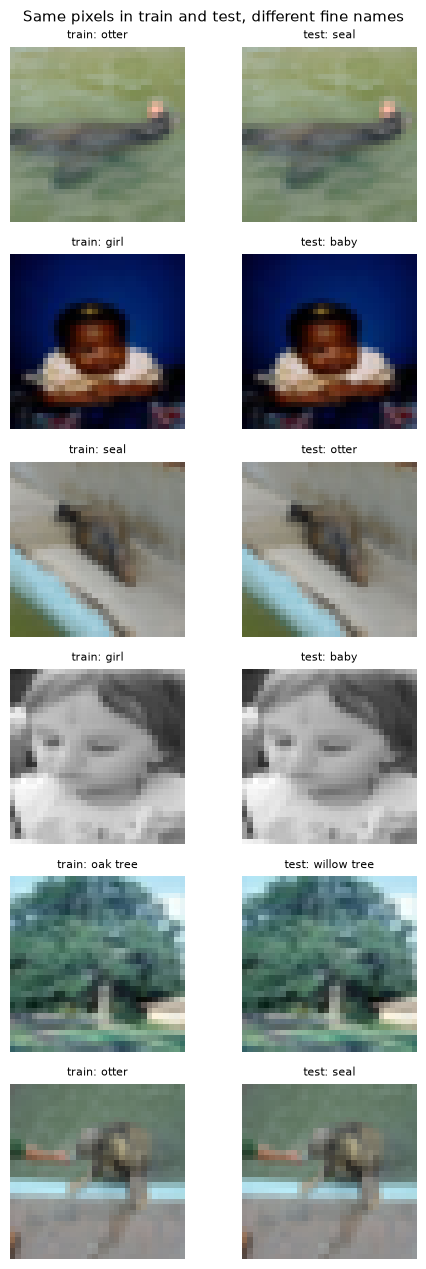

near copies shared by train and test (fingerprint match and mean abs diff < 8): 3


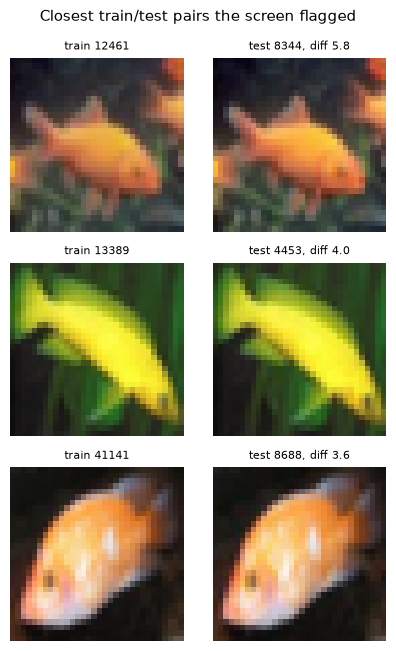

In [17]:
def packed_rows(images):
    flat = np.ascontiguousarray(images).reshape(len(images), -1)
    row_type = np.dtype((np.void, flat.shape[1] * flat.dtype.itemsize))
    return flat.view(row_type).ravel()


def average_hash(images):
    gray = images.astype(np.float32).mean(axis=3)
    small = gray.reshape(len(images), 8, 4, 8, 4).mean(axis=(2, 4))
    above = small > small.mean(axis=(1, 2), keepdims=True)
    weights = (2 ** np.arange(64, dtype=np.uint64)).reshape(1, 8, 8)
    return (above.astype(np.uint64) * weights).sum(axis=(1, 2))


def mean_abs_diff(left, right):
    return float(np.mean(np.abs(left.astype(np.int16) - right.astype(np.int16))))


train_packed = packed_rows(train_images)
test_packed = packed_rows(test_images)
_train_unique, train_exact_counts = np.unique(train_packed, return_counts=True)
_test_unique, test_exact_counts = np.unique(test_packed, return_counts=True)
exact_overlap = np.intersect1d(train_packed, test_packed)

print("extra exact copies inside train:", int((train_exact_counts - 1).sum()))
print("extra exact copies inside test: ", int((test_exact_counts - 1).sum()))
print("exact copies shared by train and test:", len(exact_overlap))

exact_pairs = []
test_by_bytes = {}
for index, key in enumerate(test_packed):
    test_by_bytes.setdefault(key.tobytes(), []).append(index)
for train_index, key in enumerate(train_packed):
    for test_index in test_by_bytes.get(key.tobytes(), []):
        exact_pairs.append((train_index, test_index))

same_label_exact = sum(int(train_fine[i] == test_fine[j]) for i, j in exact_pairs)
print("  same fine name:     ", same_label_exact)
print("  different fine name:", len(exact_pairs) - same_label_exact)

train_groups = {}
for index, key in enumerate(train_packed):
    train_groups.setdefault(key.tobytes(), []).append(index)
repeated_train_groups = [indexes for indexes in train_groups.values() if len(indexes) > 1]
train_name_conflicts = sum(
    len({int(train_fine[i]) for i in indexes}) > 1 for indexes in repeated_train_groups
)
print("training photos stored more than once:", len(repeated_train_groups))
print("  of those, stored under more than one fine name:", train_name_conflicts)

conflicts = [(i, j) for i, j in exact_pairs if int(train_fine[i]) != int(test_fine[j])]
if conflicts:
    fig, axes = plt.subplots(len(conflicts), 2, figsize=(5.2, 2.15 * len(conflicts)))
    axes = np.atleast_2d(axes)
    for row, (train_index, test_index) in enumerate(conflicts):
        axes[row, 0].imshow(train_images[train_index])
        axes[row, 1].imshow(test_images[test_index])
        axes[row, 0].set_title(
            "train: " + fine_names[int(train_fine[train_index])].replace("_", " "),
            fontsize=8,
        )
        axes[row, 1].set_title(
            "test: " + fine_names[int(test_fine[test_index])].replace("_", " "),
            fontsize=8,
        )
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")
    fig.suptitle("Same pixels in train and test, different fine names", fontsize=11)
    plt.tight_layout()
    plt.show()

train_fingerprints = average_hash(train_images)
test_fingerprints = average_hash(test_images)
test_bucket = {}
for index, fingerprint in enumerate(test_fingerprints.tolist()):
    test_bucket.setdefault(fingerprint, []).append(index)

near_pairs = []
for train_index, fingerprint in enumerate(train_fingerprints.tolist()):
    for test_index in test_bucket.get(fingerprint, []):
        if train_packed[train_index] == test_packed[test_index]:
            continue
        distance = mean_abs_diff(train_images[train_index], test_images[test_index])
        if distance < 8:
            near_pairs.append((train_index, test_index, distance))

print("near copies shared by train and test (fingerprint match and mean abs diff < 8):", len(near_pairs))

if near_pairs:
    show = near_pairs[:3]
    fig, axes = plt.subplots(len(show), 2, figsize=(4.2, 2.2 * len(show)))
    axes = np.atleast_2d(axes)
    for row, (train_index, test_index, distance) in enumerate(show):
        axes[row, 0].imshow(train_images[train_index])
        axes[row, 1].imshow(test_images[test_index])
        axes[row, 0].set_title(f"train {train_index}", fontsize=8)
        axes[row, 1].set_title(f"test {test_index}, diff {distance:.1f}", fontsize=8)
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")
    fig.suptitle("Closest train/test pairs the screen flagged", fontsize=11)
    plt.tight_layout()
    plt.show()


## Step 18. Extremely dark and extremely bright images

An outlier here means an image whose average pixel is far from the rest, on the 0–255 scale. The checklist example is a photo with mean 2 in a dataset whose typical mean is near 120. This cell measures the actual minimum and maximum, counts images with mean below 10 or above 245, and shows the five darkest and five brightest training images with their fine label.

Those tails are part of the original release. The cell displays them so the tails are visible. It does not delete them.


darkest training image, mean pixel:  7.12
brightest training image, mean pixel: 246.56
training images with mean < 10:   2
training images with mean > 245:  6


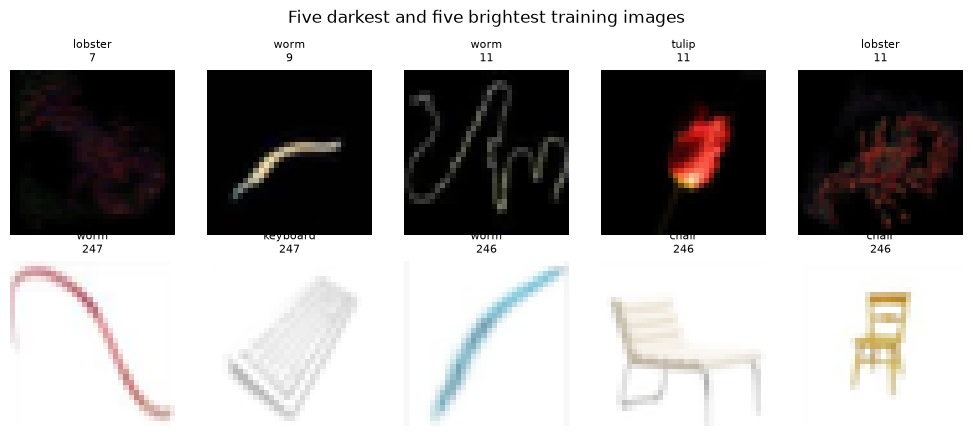

In [18]:
mean_level = train_images.astype(np.float32).mean(axis=(1, 2, 3))
order = np.argsort(mean_level)
darkest = order[:5]
brightest = order[-5:][::-1]

print("darkest training image, mean pixel:  %.2f" % mean_level[order[0]])
print("brightest training image, mean pixel: %.2f" % mean_level[order[-1]])
print("training images with mean < 10:  ", int(np.sum(mean_level < 10)))
print("training images with mean > 245: ", int(np.sum(mean_level > 245)))

fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for column, index in enumerate(darkest):
    axes[0, column].imshow(train_images[index])
    axes[0, column].set_title(
        "%s\n%.0f" % (fine_names[int(train_fine[index])].replace("_", " "), mean_level[index]),
        fontsize=8,
    )
    axes[0, column].axis("off")
for column, index in enumerate(brightest):
    axes[1, column].imshow(train_images[index])
    axes[1, column].set_title(
        "%s\n%.0f" % (fine_names[int(train_fine[index])].replace("_", " "), mean_level[index]),
        fontsize=8,
    )
    axes[1, column].axis("off")
axes[0, 0].set_ylabel("darkest", fontsize=9)
fig.suptitle("Five darkest and five brightest training images", fontsize=12)
plt.tight_layout()
plt.show()


## Step 19. Augmentations: which ones keep the label

Training will not feed the raw 0–255 image to the network. Each training step builds a new view, then scales it. The DKD CIFAR-100 recipe, which this project follows, uses only two random views:

1. **Pad with a black border of 4 pixels, then crop 32×32 at a random position.** The object stays in the frame and shifts a little. The black border is the zero fill from that recipe.
2. **Flip left-right with probability 1/2.** An apple and a chair are still an apple and a chair after a left-right flip.

The test view does none of that. Test is the original photo, scaled and normalized. The first panel is that test view.

The last three panels are views this project will not train on. They are here so the failure mode is visible:

- **Upside-down.** A vertical flip is still the same class name, and it is outside the recipe.
- **Strong color shift.** Pushing red up and green down changes the picture more than CIFAR lighting does. The recipe has no color jitter.
- **Corner crop, enlarged.** Keeping only the top-left quarter can cut the object out. A 4-pixel pad cannot do that. A heavy crop of a 32×32 photo can.

Under the figure, one training view is turned into the tensor the network would actually receive: float values, shape `(3, 32, 32)`, after subtracting the recipe mean and dividing by the recipe standard deviation. Those floats are centered near zero. They are not pixels you display.


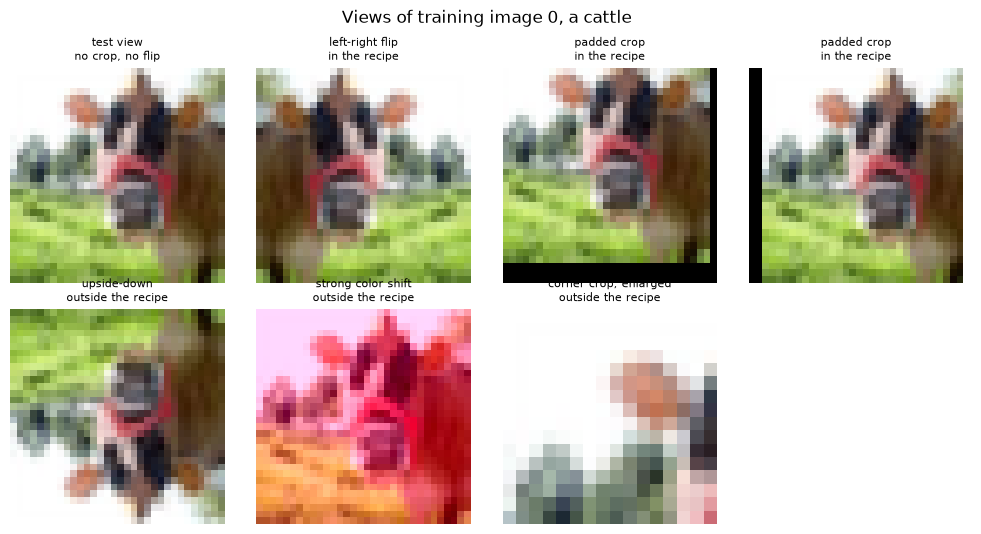

pixels on screen: uint8 (32, 32, 3) min 1 max 255
tensor for the model: float32 (3, 32, 32)
tensor min / max: -1.79 / 2.03
tensor channel means (R, G, B): [0.315 0.375 0.043]


In [19]:
def pad_and_random_crop(image, rng, pad=4):
    # Same window as RandomCrop(32, padding=4): pad, then a 32x32 crop.
    padded = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode="constant")
    top = int(rng.integers(0, 2 * pad + 1))
    left = int(rng.integers(0, 2 * pad + 1))
    return padded[top : top + 32, left : left + 32]


example = train_images[0]
example_name = fine_names[int(train_fine[0])].replace("_", " ")
crop_rng = np.random.default_rng(0)

corner = example[:16, :16].repeat(2, axis=0).repeat(2, axis=1)
shifted = example.astype(np.int16)
shifted[:, :, 0] = np.clip(shifted[:, :, 0] + 90, 0, 255)
shifted[:, :, 1] = np.clip(shifted[:, :, 1] - 40, 0, 255)
shifted = shifted.astype(np.uint8)

panels = [
    (example, "test view\nno crop, no flip"),
    (example[:, ::-1, :], "left-right flip\nin the recipe"),
    (pad_and_random_crop(example, crop_rng), "padded crop\nin the recipe"),
    (pad_and_random_crop(example, crop_rng), "padded crop\nin the recipe"),
    (example[::-1, :, :], "upside-down\noutside the recipe"),
    (shifted, "strong color shift\noutside the recipe"),
    (corner, "corner crop, enlarged\noutside the recipe"),
]

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for ax, (image, title) in zip(axes.ravel(), panels):
    ax.imshow(image)
    ax.set_title(title, fontsize=8)
    ax.axis("off")
axes.ravel()[-1].axis("off")
fig.suptitle(f"Views of training image 0, a {example_name}", fontsize=12)
plt.tight_layout()
plt.show()

scaled = example.astype(np.float32) / 255.0
normalized = (scaled - RECIPE_MEAN.astype(np.float32)) / RECIPE_STD.astype(np.float32)
model_tensor = np.transpose(normalized, (2, 0, 1))
print("pixels on screen: uint8", example.shape, "min", int(example.min()), "max", int(example.max()))
print("tensor for the model: float32", model_tensor.shape)
print("tensor min / max: %.2f / %.2f" % (float(model_tensor.min()), float(model_tensor.max())))
print("tensor channel means (R, G, B):", np.round(model_tensor.mean(axis=(1, 2)), 3))


## What this EDA measured

| Quantity | Result on the original files |
|---|---|
| Training images | 50,000 |
| Validation images | 0. The release has no validation file. |
| Test images | 10,000 |
| Fine classes | 100, with names in `meta` |
| Superclasses | 20, five fine classes each |
| Image size | 32 × 32 × 3, integers 0–255 |
| Train images per fine class | 500 in every class |
| Test images per fine class | 100 in every class |
| Missing pixels | none. Min is 0 and max is 255. |

The metric that follows from the balanced counts, and the metric in the DKD paper's CIFAR-100 tables, is **top-1 accuracy**. Every class has the same number of images, so accuracy is not being inflated by one big class.


The duplicate cell finds a small number of exact repeated photos. A few of those repeats sit in both the training file and the test file, and a few were given different fine names. They stay in the data, because this is the official release the paper evaluated.

Channel means, duplicate counts, extreme-image counts, and the PCA variance shares are printed by the cells that compute them (Steps 15–18) and again by the checklist cell below. Read those printed lines after a full run. They are measurements of this file, not targets we were aiming at.

## What this EDA did not do

- No subset. All 60,000 images stay. The PCA picture draws 4,000 of them so the cloud can be read.
- No resize of the stored data. The photos are already 32×32, which is the size the paper uses.
- No change to the files from the augmentation pictures. Those panels are examples. The training transforms live in `notebooks/01_cifar100_pipeline.ipynb`.
- No trained model and no accuracy number. PCA only redraws the pixels. There is nothing to score until a model is trained.


In [20]:
print("train / validation / test:", len(train_images), 0, len(test_images))
print("image shape and dtype:", train_images.shape[1:], train_images.dtype)
print("fine classes / superclasses:", len(fine_names), len(coarse_names))
print("train per fine class, min/max:", int(train_per_class.min()), int(train_per_class.max()))
print("channel mean:", np.round(channel_mean, 4))
print("channel std: ", np.round(channel_std, 4))
print("exact train/test copies:", len(exact_overlap))
print("  same fine name / different fine name:", same_label_exact, len(exact_pairs) - same_label_exact)
print("near train/test copies: ", len(near_pairs))
print("PCA sample:", sample_size, " axes for 90% variance:", components_for_90)


train / validation / test: 50000 0 10000
image shape and dtype: (32, 32, 3) uint8
fine classes / superclasses: 100 20
train per fine class, min/max: 500 500
channel mean: [0.5071 0.4865 0.4409]
channel std:  [0.2673 0.2564 0.2762]
exact train/test copies: 10
  same fine name / different fine name: 4 6
near train/test copies:  3
PCA sample: 4000  axes for 90% variance: 85
